# Exploratory Data Analysis (EDA): Students Performance in Exams

**Dataset:** Students Performance in Exams (Kaggle)  
**Kaggle source:** https://www.kaggle.com/datasets/spscientist/students-performance-in-exams  
**Goal:** Explore student scores and investigate how scores vary with preparation, lunch type, and demographic categories using Pandas and Matplotlib.

> This notebook downloads a public mirror of the dataset for convenience. The Kaggle page above is the dataset's reference/source page. If the mirror is unavailable, download `StudentsPerformance.csv` from Kaggle and upload it to the notebook session.

## 1. Setup and load the data

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DATA_URL = "https://gist.githubusercontent.com/withered-flowers/2d1767eff243f55b53f1d10de3952a0f/raw/students_performance.csv"

df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 2. Structural overview

In [18]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nDataFrame info and memory usage:")
df.info(memory_usage="deep")
print("\nMemory usage by column (bytes):")
display(df.memory_usage(deep=True).to_frame("memory_bytes"))
print("\nFirst five rows:")
display(df.head())
print("\nLast five rows:")
display(df.tail())

Shape: (1000, 8)

Column names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Data types:


,dtype
gender,object
race/ethnicity,object
parental level of education,object
lunch,object
test preparation course,object
math score,int64
reading score,int64
writing score,int64



DataFrame info and memory usage:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 303.7 KB

Memory usage by column (bytes):


,memory_bytes
Index,132
gender,54036
race/ethnicity,56000
parental level of education,63619
lunch,58420
test preparation course,54790
math score,8000
reading score,8000
writing score,8000



First five rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



Last five rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


## 3. Missing-value analysis

,missing_count,missing_percent
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


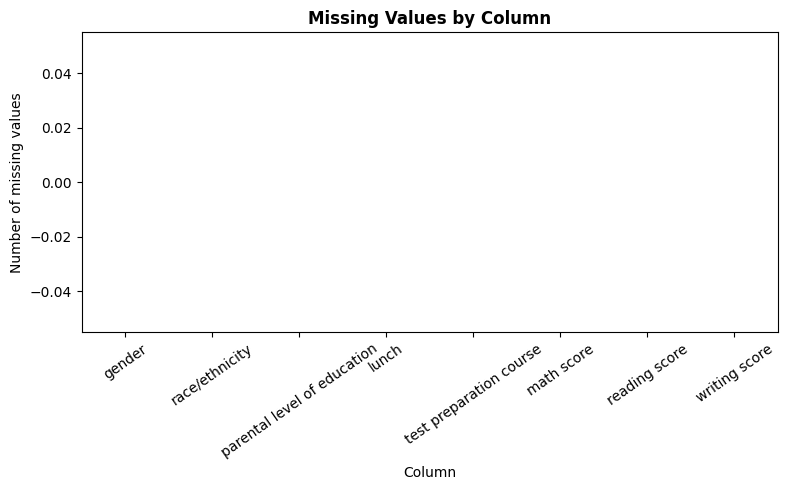

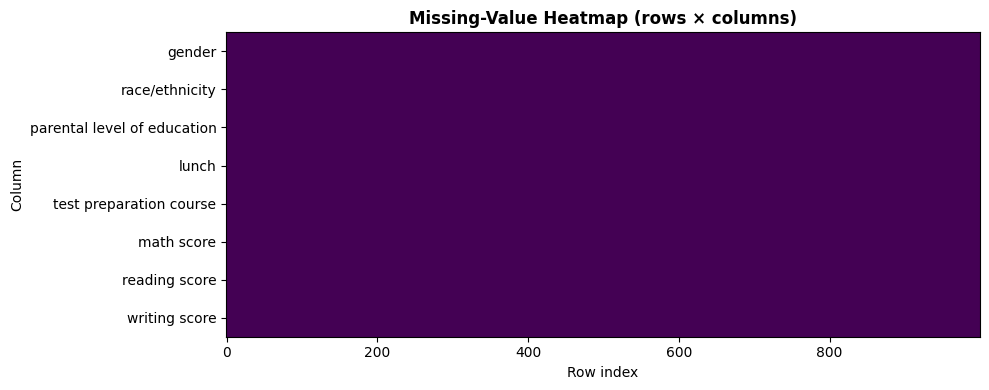

Interpretation: Check the count and heatmap above to identify columns or records with missing values. In this dataset, the columns are typically complete; if so, no missing-value imputation is needed.


In [19]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct
})

display(missing_summary)

fig, ax = plt.subplots()
missing_summary["missing_count"].plot(kind="bar", ax=ax)
ax.set_title("Missing Values by Column")
ax.set_xlabel("Column")
ax.set_ylabel("Number of missing values")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(df.isna().to_numpy().T, aspect="auto", interpolation="nearest")
ax.set_title("Missing-Value Heatmap (rows × columns)")
ax.set_xlabel("Row index")
ax.set_ylabel("Column")
ax.set_yticks(range(len(df.columns)))
ax.set_yticklabels(df.columns)
plt.tight_layout()
plt.show()

print("Interpretation: Check the count and heatmap above to identify columns or records with missing values. In this dataset, the columns are typically complete; if so, no missing-value imputation is needed.")

## 4. Summary statistics and categorical value counts

In [20]:
numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(exclude="number").columns

print("Numeric summary (mean, standard deviation, quartiles, etc.):")
display(df[numeric_cols].describe().T)
print("\nMedian of numeric columns:")
display(df[numeric_cols].median().to_frame("median"))

print("\nValue counts for categorical columns:")
for col in categorical_cols:
    print(f"\n{col}:")
    display(df[col].value_counts(dropna=False).to_frame("count"))

Numeric summary (mean, standard deviation, quartiles, etc.):


,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.089,15.163080,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.169,14.600192,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.054,15.195657,10.0,57.75,69.0,79.0,100.0



Median of numeric columns:


,median
math score,66.0
reading score,70.0
writing score,69.0



Value counts for categorical columns:

gender:


...

,count
parental level of education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



lunch:


,count
lunch,
standard,645
free/reduced,355



test preparation course:


,count
test preparation course,
none,642
completed,358


## 5. Visualisation 1 — How are exam scores distributed?

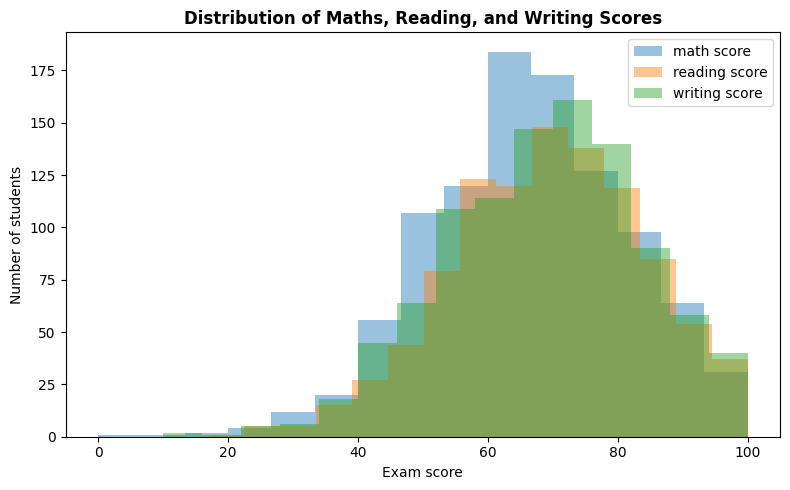

In [21]:
score_cols = ["math score", "reading score", "writing score"]
fig, ax = plt.subplots()
for col in score_cols:
    ax.hist(df[col], bins=15, alpha=0.45, label=col)
ax.set_title("Distribution of Maths, Reading, and Writing Scores")
ax.set_xlabel("Exam score")
ax.set_ylabel("Number of students")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Compare the three overlapping distributions to see which subject tends to have higher or lower scores and whether scores cluster around the middle or extremes. The distribution also reveals whether very low or very high scores are relatively uncommon.

## 6. Visualisation 2 — How strongly do subject scores relate?

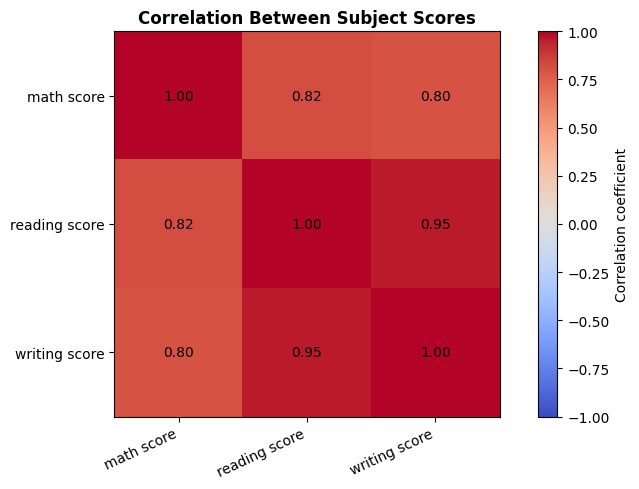

In [22]:
corr = df[score_cols].corr()
fig, ax = plt.subplots()
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(score_cols)))
ax.set_xticklabels(score_cols, rotation=25, ha="right")
ax.set_yticks(range(len(score_cols)))
ax.set_yticklabels(score_cols)
ax.set_title("Correlation Between Subject Scores")
for i in range(len(score_cols)):
    for j in range(len(score_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation coefficient")
plt.tight_layout()
plt.show()

**Interpretation:** Positive correlations mean students who score well in one subject also tend to score well in another. The strongest off-diagonal value identifies the pair of subjects whose scores move together most closely; correlation does not prove that one score causes another.

## 7. Visualisation 3 — Does test preparation relate to scores?

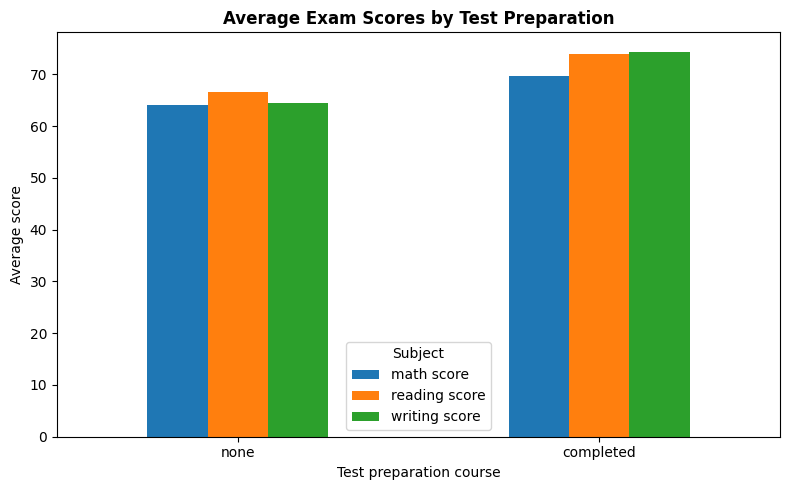

,math score,reading score,writing score
test preparation course,,,
none,64.08,66.53,64.50
completed,69.70,73.89,74.42


In [23]:
prep_order = [x for x in ["none", "completed"] if x in df["test preparation course"].unique()]
prep_means = df.groupby("test preparation course")[score_cols].mean().reindex(prep_order)
ax = prep_means.plot(kind="bar")
ax.set_title("Average Exam Scores by Test Preparation")
ax.set_xlabel("Test preparation course")
ax.set_ylabel("Average score")
ax.legend(title="Subject")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
display(prep_means.round(2))

**Interpretation:** Compare the average scores for students who completed the preparation course with those who did not. If the completed group scores higher, that is an association in this dataset—not proof that the course alone caused the difference, because other factors may matter.

## 8. Visualisation 4 — Does lunch type relate to maths scores?

/tmp/ipykernel_3806/4118883810.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=lunch_order)


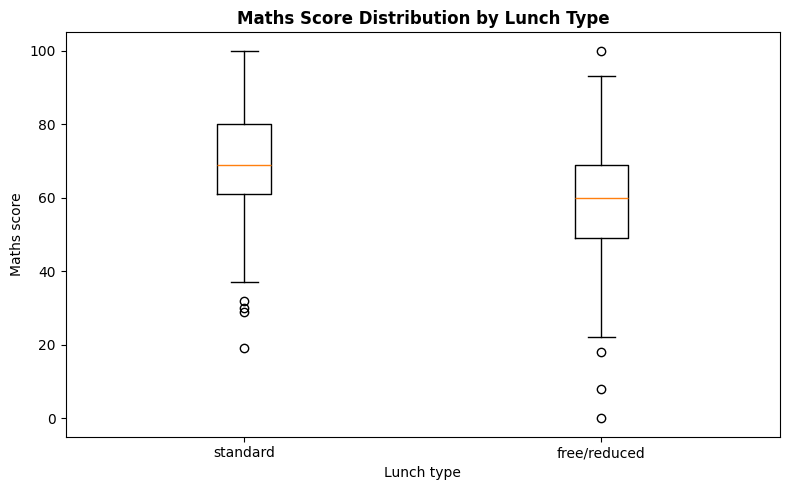

In [24]:
lunch_order = [x for x in ["standard", "free/reduced"] if x in df["lunch"].unique()]
groups = [df.loc[df["lunch"] == category, "math score"].dropna() for category in lunch_order]
fig, ax = plt.subplots()
ax.boxplot(groups, labels=lunch_order)
ax.set_title("Maths Score Distribution by Lunch Type")
ax.set_xlabel("Lunch type")
ax.set_ylabel("Maths score")
plt.tight_layout()
plt.show()

**Interpretation:** The boxplot compares the median, spread, and potential outliers in maths scores across lunch categories. Any difference should be described as an observed association, not as evidence that lunch type itself determines performance.

## 9. Visualisation 5 — How do average scores vary by parental education?

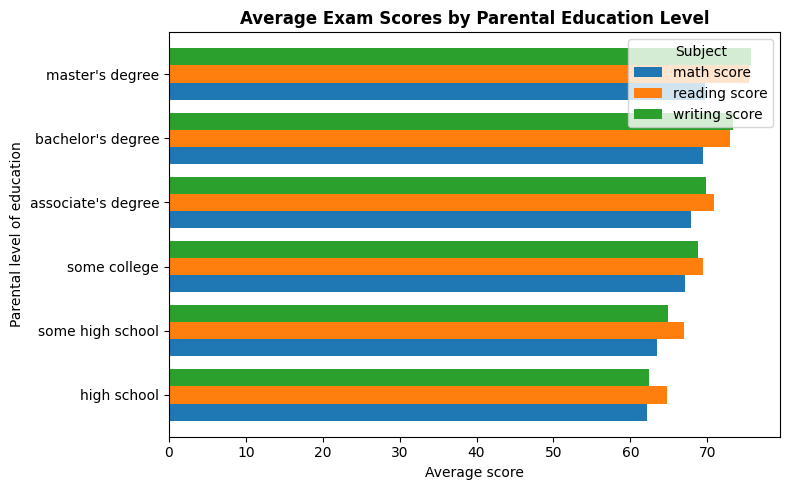

,math score,reading score,writing score
parental level of education,,,
high school,62.14,64.70,62.45
some high school,63.50,66.94,64.89
some college,67.13,69.46,68.84
associate's degree,67.88,70.93,69.90
bachelor's degree,69.39,73.00,73.38
master's degree,69.75,75.37,75.68


In [25]:
parent_means = df.groupby("parental level of education")[score_cols].mean().sort_values("reading score")
ax = parent_means.plot(kind="barh", width=0.8)
ax.set_title("Average Exam Scores by Parental Education Level")
ax.set_xlabel("Average score")
ax.set_ylabel("Parental level of education")
ax.legend(title="Subject")
plt.tight_layout()
plt.show()
display(parent_means.round(2))

**Interpretation:** This chart compares average scores across parental education categories and subjects. Look for broad patterns across categories while remembering that parental education is only one characteristic and the chart does not establish causation.

## 10. Visualisation 6 — Which gender has the higher average score by subject?

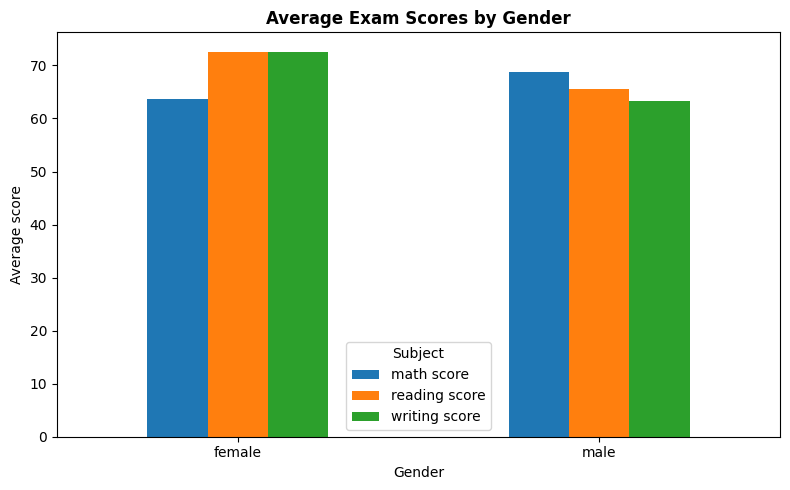

,math score,reading score,writing score
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


In [26]:
gender_means = df.groupby("gender")[score_cols].mean()
ax = gender_means.plot(kind="bar")
ax.set_title("Average Exam Scores by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Average score")
ax.legend(title="Subject")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
display(gender_means.round(2))

## 11. Findings Summary

1. **Dataset quality:** The dataset contains 1,000 rows and 8 columns, including 5 categorical columns and 3 numerical columns. No missing values were found, so data imputation was not required.

2. **Score distributions:** Reading had the highest average score at 69.17, followed by writing at 68.05 and mathematics at 66.09. This indicates that students scored higher on average in reading than in the other two subjects.

3. **Subject relationships:** Reading and writing scores have the strongest positive correlation (approximately 0.95). This suggests that students with higher reading scores generally tend to have higher writing scores.

4. **Test preparation:** Students who completed the test preparation course had higher average scores in all three subjects. Their averages were 69.70 in mathematics, 73.89 in reading, and 74.42 in writing, compared with 64.08, 66.53, and 64.50, respectively, for students who did not complete it. This is an association and does not establish causation.

5. **Group differences:** Students whose parents had a master's degree had the highest average reading score (75.37) and writing score (75.68) among the parental education categories. This shows an association between parental education category and average scores, not proof of a causal relationship.

## Conclusion

This exploratory data analysis used Python, Pandas, NumPy, and Matplotlib to examine a real-world student performance dataset. The analysis covered dataset structure, memory usage, missing values, descriptive statistics, categorical distributions, score distributions, correlations, and group comparisons. The findings highlight patterns in student performance and demonstrate the value of EDA in understanding data before further analysis.
